# 01 — Exploratory data analysis

UK used-car listings for 9 brands (scraped 2020). Source: Kaggle `adityadesai13/used-car-dataset-ford-and-mercedes`.

In [1]:
import sys; sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import pandas as pd
from src.data import load

BLUE, INK, GRID = "#2a78d6", "#52514e", "#e4e3df"
plt.rcParams.update({
    "axes.edgecolor": GRID, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "axes.formatter.use_locale": False, "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.dpi": 110,
})

from matplotlib.ticker import StrMethodFormatter
THOUSANDS = StrMethodFormatter("{x:,.0f}")

df = load()
df.shape

(97711, 11)

In [2]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,brand,age
0,A1,2017,12500,Manual,15735,Petrol,150,55.4,1.4,Audi,3
1,A6,2016,16500,Automatic,36203,Diesel,20,64.2,2.0,Audi,4
2,A1,2016,11000,Manual,29946,Petrol,30,55.4,1.4,Audi,4
3,A4,2017,16800,Automatic,25952,Diesel,145,67.3,2.0,Audi,3
4,A3,2019,17300,Manual,1998,Petrol,145,49.6,1.0,Audi,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 97711 entries, 0 to 97710
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   model         97711 non-null  object  
 1   year          97711 non-null  int64   
 2   price         97711 non-null  int64   
 3   transmission  97711 non-null  category
 4   mileage       97711 non-null  int64   
 5   fuelType      97711 non-null  category
 6   tax           97711 non-null  int64   
 7   mpg           97711 non-null  float64 
 8   engineSize    97445 non-null  float64 
 9   brand         97711 non-null  category
 10  age           97711 non-null  int64   
dtypes: category(3), float64(2), int64(5), object(1)
memory usage: 6.2+ MB


In [4]:
df.describe().round(1)

,year,price,mileage,tax,mpg,engineSize,age
count,97711.0,97711.0,97711.0,97711.0,97711.0,97445.0,97711.0
mean,2017.1,16773.6,23219.2,120.1,55.2,1.7,2.9
std,2.1,9868.5,21060.7,63.4,16.2,0.6,2.1
min,1970.0,450.0,1.0,0.0,0.3,0.0,0.0
25%,2016.0,9999.0,7673.0,125.0,47.1,1.2,1.0
50%,2017.0,14470.0,17682.0,145.0,54.3,1.6,3.0
75%,2019.0,20750.0,32500.0,145.0,62.8,2.0,4.0
max,2020.0,159999.0,323000.0,580.0,470.8,6.6,50.0


## Listings and price by brand

In [5]:
df.groupby("brand", observed=True).agg(
    listings=("price", "size"),
    median_price=("price", "median"),
    median_mileage=("mileage", "median"),
    median_year=("year", "median"),
).sort_values("median_price")

,listings,median_price,median_mileage,median_year
brand,,,,
Vauxhall,13258,9998.0,19000.0,2017.0
Toyota,6699,10798.0,18571.0,2017.0
Ford,17810,11289.5,18277.0,2017.0
Hyundai,4774,11992.5,17627.0,2017.0
Skoda,6188,12998.0,14665.0,2018.0
Volkswagen,14893,15494.0,16558.0,2017.0
Audi,10565,20000.0,19268.0,2017.0
BMW,10664,20261.5,18783.0,2017.0
Mercedes,12860,22299.0,15448.5,2018.0


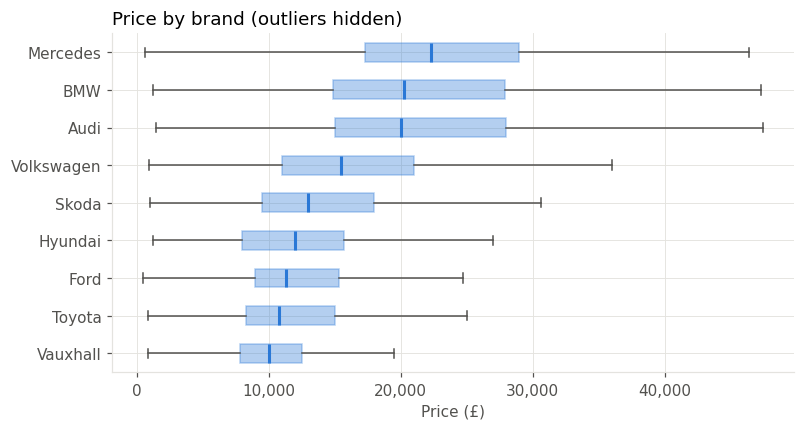

In [6]:
order = df.groupby("brand", observed=True).price.median().sort_values().index
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([df.loc[df.brand == b, "price"] for b in order], tick_labels=order, vert=False,
           showfliers=False, patch_artist=True,
           boxprops=dict(facecolor=BLUE, edgecolor=BLUE, alpha=0.35),
           medianprops=dict(color=BLUE, linewidth=2), whiskerprops=dict(color=INK), capprops=dict(color=INK))
ax.xaxis.set_major_formatter(THOUSANDS)
ax.set_xlabel("Price (£)"); ax.set_title("Price by brand (outliers hidden)", loc="left")
plt.show()

## Price distribution

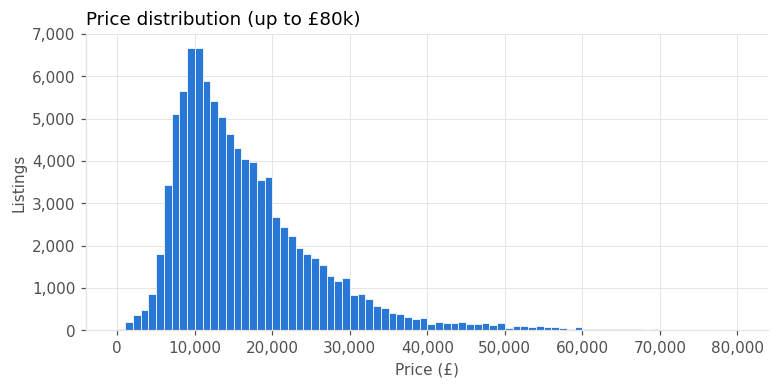

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df.price, bins=80, range=(0, 80_000), color=BLUE, edgecolor="white", linewidth=0.5)
ax.xaxis.set_major_formatter(THOUSANDS); ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_xlabel("Price (£)"); ax.set_ylabel("Listings"); ax.set_title("Price distribution (up to £80k)", loc="left")
plt.show()

## How price relates to age and mileage

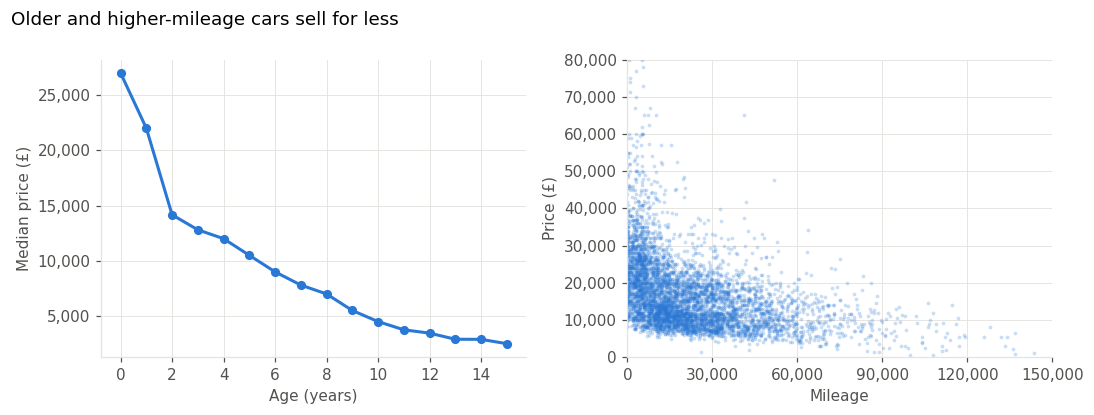

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
by_age = df[df.age <= 15].groupby("age").price.median()
axes[0].plot(by_age.index, by_age.values, color=BLUE, linewidth=2, marker="o", markersize=5)
axes[0].set_xlabel("Age (years)"); axes[0].set_ylabel("Median price (£)")
s = df.sample(5000, random_state=0)
axes[1].scatter(s.mileage, s.price, s=6, alpha=0.25, color=BLUE, linewidths=0)
axes[1].set_xlabel("Mileage"); axes[1].set_ylabel("Price (£)")
axes[1].set_xlim(0, 150_000); axes[1].set_ylim(0, 80_000)
fig.suptitle("Older and higher-mileage cars sell for less", x=0.01, ha="left")
for a in axes: a.yaxis.set_major_formatter(THOUSANDS)
axes[1].xaxis.set_major_formatter(THOUSANDS); axes[1].set_xticks(range(0, 150_001, 30_000))
plt.tight_layout(); plt.show()

In [9]:
df[["price", "year", "mileage", "tax", "mpg", "engineSize"]].corr().round(2)

,price,year,mileage,tax,mpg,engineSize
price,1.00,0.49,-0.42,0.31,-0.30,0.65
year,0.49,1.00,-0.74,0.19,-0.13,-0.04
mileage,-0.42,-0.74,1.00,-0.22,0.18,0.11
tax,0.31,0.19,-0.22,1.00,-0.45,0.28
mpg,-0.30,-0.13,0.18,-0.45,1.00,-0.26
engineSize,0.65,-0.04,0.11,0.28,-0.26,1.00


## Categorical breakdowns

In [10]:
for col in ["transmission", "fuelType"]:
    display(df.groupby(col, observed=True).price.agg(["size", "median"]).sort_values("size", ascending=False))

,size,median
transmission,,
Manual,55502,11000.0
Semi-Auto,22296,22250.0
Automatic,19904,19245.0
Other,9,15999.0


,size,median
fuelType,,
Petrol,53981,11998.0
Diesel,40419,17000.0
Hybrid,3059,18200.0
Other,246,16450.0
Electric,6,16687.5


## Open questions / next steps

- Outliers: mpg values above 150 (probably plug-in hybrids), very cheap or very old cars.
- `tax == 0` on ~6k rows: real (low-emission cars) or missing?
- A first model: predict `price` from brand, model, age, mileage, fuel, transmission, engine size.